# Course 13: Machine Learning for Agriculture and Climate
## Session 8: Floods: mapping and forecasting

**Goal:** map flood water in synthetic radar images with Otsu's threshold and a small U-Net, score the maps with pixel accuracy and IoU, test them under a calibration shift, and compare an LSTM with a linear-reservoir model for river flow using the Nash–Sutcliffe efficiency.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Synthetic radar scenes
Monsoon floods come with clouds, so optical satellites often see nothing. **Synthetic aperture radar (SAR)**, such as Sentinel-1, sends microwave pulses and records the echo, the **backscatter**, through cloud, by day and by night. Calm water reflects the pulse away like a mirror, so it looks **dark**; fields and trees scatter some energy back; buildings bounce it straight back and look **bright**. Smooth sand and dry bare soil also look dark, which fools simple methods.

Radar images are grainy because echoes from many small scatterers in one pixel interfere. This **speckle** multiplies the true backscatter: with $L$ looks (averages), the measured intensity is the true backscatter times a Gamma($L$, $1/L$) random number with mean 1. We use $L = 4$ and work in decibels, $10 \log_{10}$ of the intensity.

**The scenes are synthetic.** Each 64 × 64 scene has fields with different backscatter, a meandering river, flooded fields near the river (more in some scenes than others), sandbars beside the river (dark but dry) and a few bright buildings. They stand in for the Sentinel-1 chips of Sen1Floods11 (section 6). In section 3 we also make every test scene 3 dB darker, as if it came from a different calibration or viewing angle.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, optimize
import torch
import torch.nn as nn
import torch.nn.functional as Fnn

t_start = time.time()
torch.set_num_threads(1)
torch.manual_seed(0)
np.random.seed(0)

N, LOOKS = 64, 4

def scene(rng):
    """One synthetic radar scene in dB and its true water mask."""
    yy, xx = np.mgrid[0:N, 0:N].astype(float)
    k = rng.integers(10, 18)                                             # fields: a random Voronoi partition
    seeds = rng.uniform(0, N, (k, 2))
    field = ((yy[..., None] - seeds[:, 0]) ** 2 + (xx[..., None] - seeds[:, 1]) ** 2).argmin(-1)
    db = rng.uniform(-11, -6, k)[field] + rng.normal(0, 0.8, (N, N))     # land backscatter, -11 to -6 dB
    x0, amp, per, ph, w = rng.uniform(0.25, 0.75) * N, rng.uniform(2, 8), rng.uniform(25, 60), rng.uniform(0, 2 * np.pi), rng.uniform(1.0, 2.5)
    centre = lambda y: x0 + amp * np.sin(2 * np.pi * y / per + ph)     # the river's centre line
    river = np.abs(xx - centre(yy)) < w
    severity = rng.beta(1, 2)                                            # most scenes have a small flood
    near = np.abs(seeds[:, 1] - centre(seeds[:, 0])) < 3 + 15 * severity
    flooded = near & (rng.random(k) < 0.25 + 0.5 * severity)
    water = river | (flooded[field] & (np.abs(xx - centre(yy)) < 6 + 20 * severity))
    sand = np.zeros((N, N), bool)                                        # sandbars beside the river: dark but dry
    for _ in range(rng.integers(0, 3)):
        cy, cx = rng.uniform(0, N), centre(rng.uniform(0, N)) + rng.choice([-1, 1]) * rng.uniform(4, 10)
        sand |= ((yy - cy) / rng.uniform(3, 7)) ** 2 + ((xx - cx) / rng.uniform(2, 4)) ** 2 < 1
    sand &= ~water
    bld = np.zeros((N, N), bool)                                         # small bright buildings
    for _ in range(rng.integers(0, 6)):
        cy, cx = rng.integers(0, N - 3, 2)
        bld[cy:cy + rng.integers(2, 4), cx:cx + rng.integers(2, 4)] = True
    bld &= ~water
    db[water] = rng.normal(-20, 1.0, water.sum())                       # calm water: about -20 dB
    db[sand] = -16 + rng.normal(0, 1.0, sand.sum())
    db[bld] = rng.normal(0, 2.0, bld.sum())
    intensity = 10 ** (db / 10) * rng.gamma(LOOKS, 1 / LOOKS, (N, N))   # multiplicative speckle
    return 10 * np.log10(intensity), water

rng = np.random.default_rng(0)
def make(n):
    s = [scene(rng) for _ in range(n)]
    return np.stack([a for a, b in s]), np.stack([b for a, b in s])

X_tr, Y_tr = make(200)                 # training scenes (with labels)
X_te, Y_te = make(50)                  # test scenes of the same kind
frac = Y_te.mean(axis=(1, 2))
print(f"water fraction: training {Y_tr.mean():.3f}, test {Y_te.mean():.3f}; per test scene from {frac.min():.3f} to {frac.max():.3f} "
      f"(median {np.median(frac):.3f}); {np.sum(frac < 0.05)} of 50 test scenes have under 5% water")
med = lambda x: ndimage.median_filter(x, 3)                              # a 3 x 3 median speckle filter
print(f"mean dB over test scenes: water {X_te[Y_te].mean():.1f}, not water {X_te[~Y_te].mean():.1f}; "
      f"speckle standard deviation in dB over water: {X_te[Y_te].std():.2f} raw, {np.concatenate([med(x)[y] for x, y in zip(X_te, Y_te)]).std():.2f} after the median filter")

water fraction: training 0.146, test 0.145; per test scene from 0.031 to 0.536 (median 0.115); 7 of 50 test scenes have under 5% water
mean dB over test scenes: water -20.6, not water -9.2; speckle standard deviation in dB over water: 2.53 raw, 1.44 after the median filter


### 2. Otsu's threshold, and why pixel accuracy misleads
**Otsu's method** (Otsu 1979) picks the threshold that best splits an image's histogram into two groups: it maximizes the between-class variance $w_0 w_1 (\mu_0 - \mu_1)^2$, where $w$ are the fractions of pixels on each side and $\mu$ their means. It needs no labels, but it assumes the histogram has two clear peaks, one for water and one for land.

Two scores for a water map:
* **pixel accuracy**: the fraction of pixels labelled correctly;
* **intersection over union (IoU)** for water: $|\text{predicted} \cap \text{true}| \,/\, |\text{predicted} \cup \text{true}|$, which ignores the many easy dry pixels.

We also score a useless map that says "no water anywhere", and a fixed threshold of −15 dB chosen by eye from section 1.

map                        accuracy   IoU   missed water  false water | mean IoU: scenes <5% water  others
no water anywhere            0.855   0.000     29620 px          0 px |                    0.000     0.000
Otsu, raw image              0.921   0.645        65 px      16187 px |                    0.156     0.710
Otsu, 3x3 mean filter        0.917   0.598      4194 px      12892 px |                    0.160     0.754
Otsu, 3x3 median filter      0.982   0.890       114 px       3546 px |                    0.609     0.939
Otsu, 5x5 median filter      0.950   0.734      1113 px       9200 px |                    0.224     0.876
fixed -15 dB, 3x3 median     0.992   0.947       181 px       1460 px |                    0.777     0.949


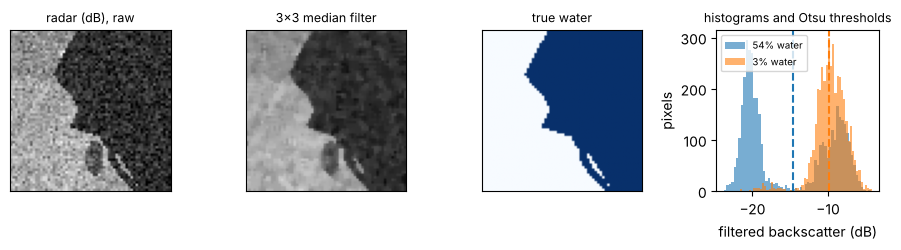

Otsu threshold (3x3 median): -14.6 dB in the scene with 54% water, -9.9 dB in the scene with 3% water


In [2]:
def otsu(values, bins=256):
    """Threshold that maximizes the between-class variance of the histogram (Otsu 1979)."""
    h, edges = np.histogram(values, bins)
    c = (edges[:-1] + edges[1:]) / 2
    w0, m0 = h.cumsum(), (h * c).cumsum()                 # pixel count and sum below each candidate threshold
    w1, m1 = w0[-1] - w0, m0[-1] - m0
    between = w0 * w1 * (m0 / np.maximum(w0, 1) - m1 / np.maximum(w1, 1)) ** 2
    return c[between.argmax()]

def scores(pred, true):
    """Pixel accuracy and water IoU pooled over all scenes, and IoU per scene."""
    per = np.array([(p & t).sum() / max((p | t).sum(), 1) for p, t in zip(pred, true)])
    return (pred == true).mean(), (pred & true).sum() / (pred | true).sum(), per

maps = {"no water anywhere": np.zeros_like(Y_te),
        "Otsu, raw image": np.stack([x < otsu(x.ravel()) for x in X_te]),
        "Otsu, 3x3 mean filter": np.stack([f < otsu(f.ravel()) for f in [10 * np.log10(ndimage.uniform_filter(10 ** (x / 10), 3)) for x in X_te]]),
        "Otsu, 3x3 median filter": np.stack([med(x) < otsu(med(x).ravel()) for x in X_te]),
        "Otsu, 5x5 median filter": np.stack([ndimage.median_filter(x, 5) < otsu(ndimage.median_filter(x, 5).ravel()) for x in X_te]),
        "fixed -15 dB, 3x3 median": np.stack([med(x) < -15 for x in X_te])}
print("map                        accuracy   IoU   missed water  false water | mean IoU: scenes <5% water  others")
for name, P in maps.items():
    acc, iou, per = scores(P, Y_te)
    print(f"{name:26s}   {acc:.3f}   {iou:.3f}  {(~P & Y_te).sum():8d} px   {(P & ~Y_te).sum():8d} px |"
          f"                    {per[frac < 0.05].mean():.3f}     {per[frac >= 0.05].mean():.3f}")

few, many = np.argmin(frac), np.argmax(frac)
fig, ax = plt.subplots(1, 4, figsize=(9, 2.6))
ax[0].imshow(X_te[many], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("radar (dB), raw", fontsize=9)
ax[1].imshow(med(X_te[many]), cmap="gray", vmin=-25, vmax=0); ax[1].set_title("3x3 median filter", fontsize=9)
ax[2].imshow(Y_te[many], cmap="Blues"); ax[2].set_title("true water", fontsize=9)
for a in ax[:3]:
    a.set_xticks([]); a.set_yticks([])
for i, lab in [(many, f"{frac[many]:.0%} water"), (few, f"{frac[few]:.0%} water")]:
    v = med(X_te[i]).ravel()
    ax[3].hist(v, bins=60, alpha=0.6, label=lab)
    ax[3].axvline(otsu(v), ls="--", color="C0" if i == many else "C1")
ax[3].set_xlabel("filtered backscatter (dB)"); ax[3].set_ylabel("pixels"); ax[3].set_title("histograms and Otsu thresholds", fontsize=9)
ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"Otsu threshold (3x3 median): {otsu(med(X_te[many]).ravel()):.1f} dB in the scene with {frac[many]:.0%} water, "
      f"{otsu(med(X_te[few]).ravel()):.1f} dB in the scene with {frac[few]:.0%} water")

### 3. A small U-Net, and a shift in calibration
A **U-Net** (Ronneberger et al. 2015) is an encoder–decoder CNN: the encoder shrinks the image to see context, the decoder grows it back to full size, and **skip connections** carry fine detail across. Ours has two levels and about 13,000 weights, trained with binary cross-entropy on the 200 labelled training scenes. The full-size version for Sen1Floods11 is much bigger.

Then the test that matters for deployment: the same 50 test scenes, made 3 dB darker. Otsu chooses a new threshold for each image; the U-Net and the fixed threshold learned their numbers from the training scenes.

U-Net: 13,033 weights, trained in 15 s


same calibration | Otsu, 3x3 median         accuracy 0.982  IoU 0.890
same calibration | fixed -15 dB, 3x3 median accuracy 0.992  IoU 0.947
same calibration | U-Net                    accuracy 0.996  IoU 0.971


3 dB darker      | Otsu, 3x3 median         accuracy 0.982  IoU 0.890
3 dB darker      | fixed -15 dB, 3x3 median accuracy 0.952  IoU 0.751
3 dB darker      | U-Net                    accuracy 0.979  IoU 0.871
U-Net mean IoU on scenes with under 5% water: 0.864


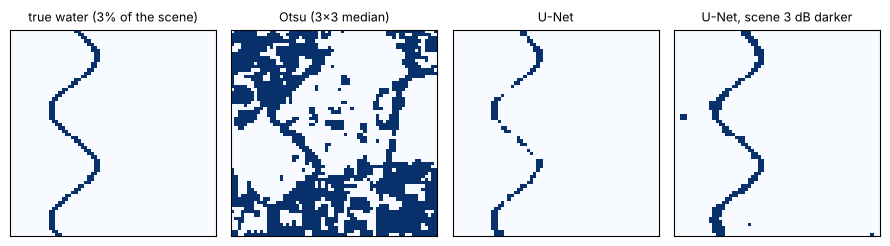

In [3]:
class SmallUNet(nn.Module):
    def __init__(self, c=12):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(1, c, 3, padding=1), nn.ReLU(), nn.Conv2d(c, c, 3, padding=1), nn.ReLU())
        self.enc2 = nn.Sequential(nn.Conv2d(c, 2 * c, 3, padding=1), nn.ReLU(), nn.Conv2d(2 * c, 2 * c, 3, padding=1), nn.ReLU())
        self.up = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
        self.dec = nn.Sequential(nn.Conv2d(2 * c, c, 3, padding=1), nn.ReLU(), nn.Conv2d(c, 1, 1))
    def forward(self, x):
        a = self.enc1(x)                                   # full resolution
        b = self.enc2(Fnn.max_pool2d(a, 2))                # half resolution: more context
        return self.dec(torch.cat([a, self.up(b)], 1))     # skip connection: concatenate fine and coarse features

mu_db, sd_db = X_tr.mean(), X_tr.std()                     # normalization learned from the training scenes
to_t = lambda X: torch.tensor((X - mu_db) / sd_db, dtype=torch.float32)[:, None]
x_tr, y_tr = to_t(X_tr), torch.tensor(Y_tr, dtype=torch.float32)[:, None]
t0 = time.time()
torch.manual_seed(0)
unet = SmallUNet()
opt = torch.optim.Adam(unet.parameters(), 3e-3)
g = torch.Generator().manual_seed(0)
for epoch in range(12):
    perm = torch.randperm(len(x_tr), generator=g)
    for b in range(0, len(x_tr), 16):
        idx = perm[b:b + 16]
        loss = Fnn.binary_cross_entropy_with_logits(unet(x_tr[idx]), y_tr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
print(f"U-Net: {sum(p.numel() for p in unet.parameters()):,} weights, trained in {time.time() - t0:.0f} s")

def unet_map(X):
    with torch.no_grad():
        return (unet(to_t(X))[:, 0] > 0).numpy()

X_sh = X_te - 3.0                                          # the same test scenes, 3 dB darker
results = {}
for test_name, X, Y in [("same calibration", X_te, Y_te), ("3 dB darker", X_sh, Y_te)]:
    for name, P in [("Otsu, 3x3 median", np.stack([med(x) < otsu(med(x).ravel()) for x in X])),
                    ("fixed -15 dB, 3x3 median", np.stack([med(x) < -15 for x in X])),
                    ("U-Net", unet_map(X))]:
        acc, iou, per = scores(P, Y)
        results[test_name, name] = P
        print(f"{test_name:16s} | {name:24s} accuracy {acc:.3f}  IoU {iou:.3f}")
acc, iou, per = scores(results["same calibration", "U-Net"], Y_te)
print(f"U-Net mean IoU on scenes with under 5% water: {per[frac < 0.05].mean():.3f}")

i = few
fig, ax = plt.subplots(1, 4, figsize=(9, 2.6))
for a, img, title in zip(ax, [Y_te[i], results["same calibration", "Otsu, 3x3 median"][i], results["same calibration", "U-Net"][i],
                              results["3 dB darker", "U-Net"][i]],
                         [f"true water ({frac[i]:.0%} of the scene)", "Otsu (3x3 median)", "U-Net", "U-Net, scene 3 dB darker"]):
    a.imshow(img, cmap="Blues", vmin=0, vmax=1); a.set_title(title, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### 4. A synthetic catchment and a linear-reservoir model
Now forecasting. A river's flow comes from rain that passes through the soil and slowly drains out. The **true catchment** here is a small nonlinear storage model, a simple version of the conceptual models hydrologists use: rain fills a soil store, and the wetter the soil, the larger the share that runs off; runoff passes through a fast store whose outflow grows faster than linearly ($k\,U^{1.5}$) and a slow groundwater store. Rain follows a monsoon season, and evaporation takes water from the soil.

We simulate ten years of daily data: years 1–7 for training, the wet season (June to October) of year 8 as the held-out test, and year 9 for a stress test with a record 4-day storm added in late August, bigger than anything in training. The flows we "observe" carry 5% measurement noise, and the rain we "observe" carries 30% gauge error, because one rain gauge rarely measures a whole catchment's rain well.

**The baseline** is the simplest conceptual model, a **linear reservoir**: a fraction $c$ of the rain enters a store $V$, and the flow is $Q = V/k$. We fit $c$ and $k$ to the training years by least squares. The data are synthetic; real catchment data, such as the CAMELS data set used by Kratzert et al. 2018, are in section 6.

In [4]:
rng = np.random.default_rng(1)
YEARS = 10
D = 365 * YEARS
doy = np.arange(D) % 365
p_wet = 0.08 + 0.62 * np.exp(-((doy - 200) / 45) ** 2)            # chance of a rainy day: highest in July
amount = 4 + 14 * np.exp(-((doy - 200) / 50) ** 2)                 # mean rain on a rainy day (mm)
rain = np.where(rng.random(D) < p_wet, rng.gamma(0.7, amount / 0.7), 0.0)
pet = 3.5 + 1.5 * np.sin(2 * np.pi * (doy - 80) / 365)             # potential evaporation (mm/day)
storm_days = 365 * 9 + np.arange(235, 239)
rain[storm_days] += [90, 140, 120, 60]                             # a record storm in late August of year 9 (stress test)

def catchment(rain, pet, smax=150.0, beta=2.0, kq=0.03, alpha=1.5, perc_max=2.0, kl=0.02):
    """The 'true' nonlinear storage model; returns daily flow in mm/day."""
    S, U, L = 75.0, 5.0, 50.0                                       # soil, fast store and slow (groundwater) store
    Q = np.zeros_like(rain)
    for t in range(len(rain)):
        P = rain[t]
        R = P * (S / smax) ** beta                                  # wetter soil -> larger share runs off
        S += P - R
        S -= min(S, pet[t] * min(1.0, S / (0.7 * smax)))            # evaporation from the soil
        if S > smax:
            R += S - smax; S = smax
        U += R
        quick = min(U, kq * U ** alpha)                             # nonlinear fast store
        perc = min(U - quick, perc_max)
        U = max(U - quick - perc, 0.0)
        L += perc
        slow = kl * L; L -= slow                                    # linear slow store
        Q[t] = quick + slow
    return Q

q_obs = catchment(rain, pet) * np.exp(rng.normal(0, 0.05, D))      # observed flow: 5% measurement noise
rain_obs = rain * np.exp(rng.normal(0, 0.3, D))                    # observed rain: 30% gauge error
train = slice(365, 365 * 8)                                        # years 1-7 (year 0 is spin-up)
test = slice(365 * 8 + 151, 365 * 8 + 304)                         # year 8, June to October
stress = slice(365 * 9 + 151, 365 * 9 + 304)                       # year 9, June to October, with the record storm
print(f"mean annual rain {rain[365:].sum() / 9:.0f} mm; runoff ratio {q_obs[365:].sum() / rain[365:].sum():.2f}")
print(f"largest daily flow: training years {q_obs[train].max():.1f} mm/day, test season {q_obs[test].max():.1f}, stress season {q_obs[stress].max():.1f}")

def nse(sim, obs):
    """Nash-Sutcliffe efficiency: 1 is perfect, 0 is no better than the mean of the observations."""
    return 1 - ((sim - obs) ** 2).sum() / ((obs - obs.mean()) ** 2).sum()

def linear_reservoir(theta, rain):
    c, k = 1 / (1 + np.exp(-theta[0])), 1 + np.exp(theta[1])     # keeps 0 < c < 1 and k > 1
    V, Q = 0.0, np.zeros_like(rain)
    for t in range(len(rain)):
        V += c * rain[t]; Q[t] = V / k; V -= Q[t]
    return Q

fit = optimize.minimize(lambda th: ((linear_reservoir(th, rain_obs)[train] - q_obs[train]) ** 2).mean(), [0.0, 1.0], method="Nelder-Mead")
q_lin = linear_reservoir(fit.x, rain_obs)
print(f"linear reservoir: c = {1 / (1 + np.exp(-fit.x[0])):.3f}, k = {1 + np.exp(fit.x[1]):.2f} days; "
      f"NSE training years {nse(q_lin[train], q_obs[train]):.3f}, test wet season {nse(q_lin[test], q_obs[test]):.3f}")

mean annual rain 1072 mm; runoff ratio 0.46
largest daily flow: training years 45.4 mm/day, test season 15.8, stress season 99.9


linear reservoir: c = 0.482, k = 6.17 days; NSE training years 0.720, test wet season 0.372


### 5. An LSTM rainfall–runoff model
A **long short-term memory (LSTM)** network reads the daily rain and evaporation in order and carries a memory, its cell state, from day to day, much as a catchment carries water in storage. Kratzert et al. 2018 showed that LSTMs can model rainfall–runoff well. Ours has 32 hidden units and is trained on random one-year windows of the training years; the first 90 days of each window only warm up the memory and are not scored. At test time it reads the whole record. We compare NSE on the held-out wet season and the peak flow of the record storm.

LSTM: 4,641 weights, trained in 2 s
NSE           training years   test wet season   stress season
linear reservoir      0.720            0.372            0.426
LSTM                  0.974            0.838            0.650
record storm: observed peak 99.9 mm/day; LSTM 41.9; linear reservoir 24.5; largest flow in training 45.4
the LSTM's output is a weighted sum of hidden values between -1 and 1, so it cannot exceed 49.3 mm/day


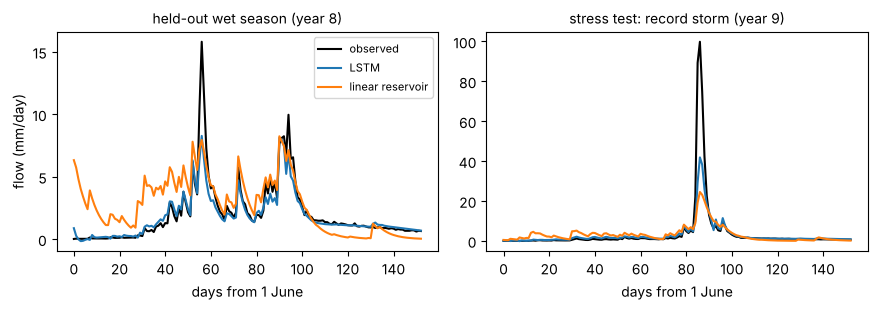

runtime so far 19 s


In [5]:
X_h = np.stack([rain_obs, pet], axis=1)
xm, xs = X_h[train].mean(0), X_h[train].std(0)
qm, qs = q_obs[train].mean(), q_obs[train].std()
X_t = torch.tensor((X_h - xm) / xs, dtype=torch.float32)
Q_t = torch.tensor((q_obs - qm) / qs, dtype=torch.float32)

class RainfallRunoffLSTM(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(2, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        return self.head(self.lstm(x)[0])[..., 0]

t0 = time.time()
torch.manual_seed(0)
lstm = RainfallRunoffLSTM()
opt = torch.optim.Adam(lstm.parameters(), 1e-2)
g = torch.Generator().manual_seed(0)
WIN, WARM, BATCH = 365, 90, 8
starts = np.arange(train.start, train.stop - WIN + 1)
for it in range(300):
    idx = starts[torch.randint(0, len(starts), (BATCH,), generator=g).numpy()][:, None] + np.arange(WIN)
    loss = ((lstm(X_t[idx])[:, WARM:] - Q_t[idx][:, WARM:]) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    if it == 200:
        for group in opt.param_groups:
            group["lr"] = 3e-3
with torch.no_grad():
    q_lstm = lstm(X_t[None])[0].numpy() * qs + qm
print(f"LSTM: {sum(p.numel() for p in lstm.parameters()):,} weights, trained in {time.time() - t0:.0f} s")
print(f"NSE           training years   test wet season   stress season")
for name, q in [("linear reservoir", q_lin), ("LSTM", q_lstm)]:
    print(f"{name:16s}      {nse(q[train], q_obs[train]):.3f}            {nse(q[test], q_obs[test]):.3f}            {nse(q[stress], q_obs[stress]):.3f}")
print(f"record storm: observed peak {q_obs[stress].max():.1f} mm/day; LSTM {q_lstm[stress].max():.1f}; linear reservoir {q_lin[stress].max():.1f}; "
      f"largest flow in training {q_obs[train].max():.1f}")
print(f"the LSTM's output is a weighted sum of hidden values between -1 and 1, so it cannot exceed "
      f"{(lstm.head.weight.abs().sum() + lstm.head.bias).item() * qs + qm:.1f} mm/day")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, sl, title in [(ax[0], test, "held-out wet season (year 8)"), (ax[1], stress, "stress test: record storm (year 9)")]:
    d = np.arange(sl.stop - sl.start)
    a.plot(d, q_obs[sl], "k", lw=1.5, label="observed")
    a.plot(d, q_lstm[sl], "C0", label="LSTM")
    a.plot(d, q_lin[sl], "C1", label="linear reservoir")
    a.set_xlabel("days from 1 June"); a.set_title(title, fontsize=10)
ax[0].set_ylabel("flow (mm/day)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 6. Real data (NOT RUN here)
**Sen1Floods11** (Bonafilia et al. 2020) has Sentinel-1 chips from 11 flood events with hand-labelled water masks, stored as GeoTIFF files in a public Google Cloud Storage bucket. The first cell reads one chip and its label and scores Otsu's method; the label uses 1 for water, 0 for no water and −1 for no data. The second trains an LSTM on real catchments with the `neuralhydrology` library, which comes from the group behind Kratzert et al. 2018; it needs the CAMELS-US data set downloaded and a configuration file as in the library's tutorials.

In [ ]:
# NOT RUN: needs rasterio and gcsfs (pip install rasterio gcsfs) and internet access to the public Sen1Floods11 bucket
import gcsfs
import rasterio

fs = gcsfs.GCSFileSystem(token="anon")
chips = sorted(fs.glob("sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/*.tif"))
print(len(chips), "hand-labelled Sentinel-1 chips")

def read(path):
    with fs.open(path, "rb") as f, rasterio.open(f) as src:
        return src.read()                                   # [band, row, column]

s1 = read(chips[0])                                         # band 0: VV backscatter in dB, band 1: VH
label = read(chips[0].replace("S1Hand", "LabelHand"))[0]   # 1 water, 0 no water, -1 no data
ok = (label >= 0) & np.isfinite(s1[0])
vv = ndimage.median_filter(np.nan_to_num(s1[0], nan=0.0), 3)
pred = vv < otsu(vv[ok])
truth = label == 1
print(f"{chips[0].split('/')[-1]}: water fraction {truth[ok].mean():.3f}, "
      f"Otsu IoU {(pred & truth & ok).sum() / ((pred | truth) & ok).sum():.3f}")

In [ ]:
# NOT RUN: needs the neuralhydrology library (pip install neuralhydrology), the CAMELS-US data set (a download of a few GB)
# and a configuration file such as the "1_basin.yml" of the library's introduction tutorial; a GPU makes it much faster
from pathlib import Path
from neuralhydrology.nh_run import start_run, eval_run

start_run(config_file=Path("1_basin.yml"))                 # trains an LSTM; writes a run directory under runs/
run_dir = sorted(Path("runs").iterdir())[-1]
eval_run(run_dir=run_dir, period="test")                   # writes NSE and other metrics for the test period

### 7. Exercises

In [6]:
# TODO: make the U-Net robust to calibration shifts. Retrain it (same architecture, same seed) with augmentation: add a
# random offset between -4 and +4 dB to each training scene before normalizing. Then score it on X_te and on X_sh.
# Does it close the gap with Otsu on the darker scenes? Does it lose anything on the normal scenes?
def train_with_offsets(max_offset_db=4.0, epochs=12):
    return None          # replace with your code; return the trained network

r = train_with_offsets()
print("not done yet" if r is None else "trained: now score it on both test sets")

not done yet


In [7]:
# TODO: an "ungauged" catchment. Simulate a second catchment with the same rain but different storage
# (for example catchment(rain, pet, smax=250.0, kq=0.015)), then apply the LSTM trained above without retraining.
# Report its NSE on year 8's wet season, and the NSE of the linear reservoir with the first catchment's c and k.
# What would a model need to see during training to transfer to new catchments?
def ungauged_test():
    return None          # replace with your code; return (nse_lstm, nse_linear_reservoir)

r = ungauged_test()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Pixel accuracy hides bad maps.** Water covered 14.5% of the test pixels, so the useless map "no water anywhere" scored 0.855 accuracy with IoU 0.000. Otsu's threshold on the raw image scored 0.921 accuracy but only 0.645 IoU: speckle (a standard deviation of 2.53 dB over water) scattered 16,187 false water pixels over the land.
2. **A speckle filter helps only if it keeps edges.** A 3 × 3 median filter cut the speckle to 1.44 dB and raised Otsu's IoU to 0.890. Against our expectation, a 3 × 3 mean filter did worse than no filter (IoU 0.598): averaging in linear units lets bright land dominate the dark water next to it, so it missed 4,194 water pixels at edges (65 without a filter). A 5 × 5 median (0.734) erased much of the narrow river.
3. **Otsu fails when there is little water.** On the 7 scenes with under 5% water its mean IoU was 0.609, against 0.939 on the others. With 3% water the histogram has one peak, and Otsu put its threshold at −9.9 dB, inside the land peak, marking much of the land as water (second figure). On these data a fixed −15 dB threshold did better (IoU 0.947), but only while the calibration stayed the same.
4. **The U-Net was best on data like its training data, and lost its lead under a shift.** It scored IoU 0.971 (0.864 on the low-water scenes). With the same scenes made 3 dB darker, Otsu was unchanged (0.890) because it re-picks its threshold for each image, the fixed threshold fell to 0.751, and the U-Net fell to 0.871, below Otsu. A model that has seen only one calibration needs testing on others before deployment.
5. **The LSTM beat the linear reservoir in a normal season.** NSE on the held-out wet season was 0.838 for the LSTM and 0.372 for the linear reservoir (0.974 and 0.720 on the training years). Both read rain with 30% gauge error, which is one reason the LSTM still missed part of some peaks.
6. **Neither model forecast the record flood.** The record storm gave an observed peak of 99.9 mm/day, more than twice the largest training flow (45.4). The LSTM predicted 41.9 and the linear reservoir 24.5, and the season's NSE fell to 0.650 and 0.426. The LSTM could not have done much better: its output is a weighted sum of hidden values between −1 and 1, which caps it at 49.3 mm/day with these weights. A model trained on one catchment's record has never seen a flood bigger than that record; training on many catchments shows it many more large floods.